# Miniproyecto 3: Conversión de Escenas Diurnas a Nocturnas con CycleGAN
**Curso:** Redes Neuronales y Deep Learning — Universidad Autónoma de Occidente  
**Objetivo:** Implementar y entrenar una red generativa adversarial cíclica (**CycleGAN**) para transferir el estilo de escenas urbanas entre el **Dominio A (Día)** y el **Dominio B (Noche)** sin necesidad de imágenes emparejadas (*unpaired image-to-image translation*), utilizando un conjunto curado de 200 imágenes por dominio.

### Técnicas Avanzadas Incorporadas para Evitar Sobreentrenamiento y Mejorar la Calidad:
1. **Regulación y Estabilización Adversarial (de *Gan_RED.ipynb*):**
   - **Label Smoothing unilateral (0.9 para etiquetas reales):** Suaviza las probabilidades del discriminador evitando gradientes extremos y colapso de modo.
   - **Dropout espacial (0.2 - 0.3) en el Discriminador PatchGAN:** Previene la memorización de texturas específicas y asegura un aprendizaje generalizado.
   - **Buffer de Replay de Imágenes Falsas (History Image Buffer, tamaño 50):** Rompe la correlación temporal y estabiliza el entrenamiento del discriminador evitando oscilaciones caóticas.
   - **LeakyReLU ($lpha=0.2$) y Optimizadores Adam ($eta_1=0.5$):** Configuración estándar de GANs estables.
2. **Alineación Estructural y Regularización (de *Autoendores_function.ipynb*):**
   - **Pérdida de Consistencia Cíclica $\mathcal{L}_{cycle}$ (tipo Autoencoder bidireccional):** $F(G(x)) pprox x$ y $G(F(y)) pprox y$ actúa como un autocodificador cruzado profundo que preserva la geometría y la estructura espacial de edificios, calles y cielo.
   - **Pérdida de Identidad $\mathcal{L}_{identity}$:** $G(y) pprox y$ y $F(x) pprox x$ preserva el espacio de color intrínseco.
   - **Decay Progresivo del Learning Rate (Schedulers):** Reduce la tasa de aprendizaje a la mitad en la segunda mitad del entrenamiento para converger suavemente hacia un óptimo sin sobreajuste.
3. **Data Augmentation Dinámico en TensorFlow:**
   - *Random Jittering* (escalado a 286x286 + recorte aleatorio a 256x256 por cada época sin caché prematuro).
   - *Random Mirroring* horizontal y normalización en $[-1, 1]$ con activación `tanh` en el generador.


In [ ]:
# Verificación de aceleración por GPU y configuración para ejecución local / Colab
# Optimizado para GPU local NVIDIA (RTX 3050 Laptop 6GB) y Google Colab
import os
import sys
import time
import random
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import clear_output, display

# Solo clonar si se ejecuta en Google Colab y el repositorio no existe localmente
if ('google.colab' in sys.modules or os.path.exists('/content')) and not os.path.exists('dataset'):
    if not os.path.exists('RepositorioMiniproyecto3'):
        !git clone https://github.com/AlanBas18/RepositorioMiniproyecto3.git
        if os.path.exists('RepositorioMiniproyecto3'):
            os.chdir('RepositorioMiniproyecto3')

import tensorflow as tf
from tensorflow.keras import layers, Model, Sequential

print("TensorFlow Version:", tf.__version__)

# Configuración de memoria dinámica (Memory Growth) para GPUs NVIDIA (RTX 3050 Laptop 6GB)
# En laptops, el sistema operativo (DWM) comparte VRAM. Habilitar 'memory_growth'
# evita que TensorFlow reserve el 100% de la VRAM al inicio y previene errores OOM.
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✅ GPU detectada: {[gpu.name for gpu in gpus]}")
        print("✅ Asignación dinámica de memoria VRAM (Memory Growth) activada con éxito.")
    except RuntimeError as e:
        print("⚠️ Aviso al configurar memoria de GPU:", e)
else:
    print("⚠️ No se detectó GPU activa en TensorFlow. Se ejecutará en CPU.")
    print("   Nota: En Windows nativo con TF >= 2.11, se recomienda WSL2 o DirectML para soporte GPU.")

Cloning into 'RepositorioMiniproyecto3'...
remote: Enumerating objects: 459, done.
remote: Counting objects: 100% (115/115), done.
remote: Compressing objects: 100% (114/114), done.
remote: Total 459 (delta 1), reused 111 (delta 0), pack-reused 344 (from 2)
Receiving objects: 100% (459/459), 780.32 MiB | 20.19 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (445/445), done.
TensorFlow Version: 2.21.0
GPU(s) disponible(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Carga, Filtrado a 200 Imágenes y Data Augmentation Dinámico
Para entrenar eficazmente el modelo con el subconjunto representativo de **200 imágenes para trainA** y **200 imágenes para trainB** (junto con el conjunto de evaluación `testA` y `testB`):
* Tomamos exactamente **200 imágenes de entrenamiento** por dominio para asegurar balance estricto.
* Aplicamos **aumento dinámico de datos** (*Data Augmentation*) en cada época: escalado a `286x286`, recorte aleatorio a `256x256` y volteo horizontal aleatorio.
* **Sin `.cache()` antes del aumento** para que cada época presente variantes geométricas nuevas a la red, evitando que los modelos memoricen las 200 imágenes.


=== Conjunto de Datos Configurado ===
Entrenamiento -> Día   (trainA): 200 imágenes
Entrenamiento -> Noche (trainB): 200 imágenes
Evaluación    -> Día   (testA):  20 imágenes
Evaluación    -> Noche (testB):  20 imágenes


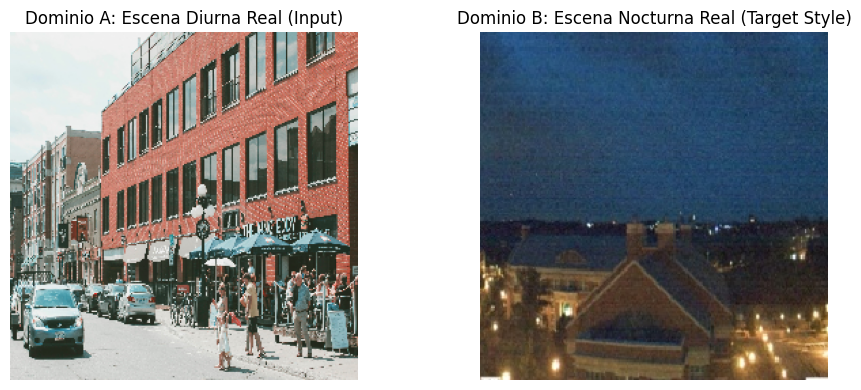

In [ ]:
# Rutas hacia el dataset con detección automática (Local en VS Code / Google Colab)
POSSIBLE_PATHS = [
    './dataset',
    'dataset',
    os.path.join(os.getcwd(), 'dataset'),
    '/content/RepositorioMiniproyecto3/dataset',
    './RepositorioMiniproyecto3/dataset'
]

BASE_DIR = next((p for p in POSSIBLE_PATHS if os.path.exists(p)), './dataset')
print(f"Directorio base del dataset seleccionado: '{BASE_DIR}'")

PATH_TRAIN_A = os.path.join(BASE_DIR, 'trainA')
PATH_TRAIN_B = os.path.join(BASE_DIR, 'trainB')
PATH_TEST_A  = os.path.join(BASE_DIR, 'testA')
PATH_TEST_B  = os.path.join(BASE_DIR, 'testB')

# Verificar que los directorios existan
for split_name, split_path in [('trainA', PATH_TRAIN_A), ('trainB', PATH_TRAIN_B), ('testA', PATH_TEST_A), ('testB', PATH_TEST_B)]:
    if not os.path.exists(split_path):
        raise FileNotFoundError(f"No se encontró la carpeta obligatoria '{split_path}'. Verifica que la ruta base '{BASE_DIR}' sea correcta.")

BUFFER_SIZE = 1000
BATCH_SIZE = 1
IMG_WIDTH = 256
IMG_HEIGHT = 256
MAX_TRAIN_SAMPLES = 200  # Exactamente 200 imágenes por dominio según el requerimiento

def load_image(image_file):
    image = tf.io.read_file(image_file)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image = tf.cast(image, tf.float32)
    return image

def normalize(image):
    # Normalización al rango [-1, 1] correspondiente a la activación tanh del generador
    return (image / 127.5) - 1.0

def random_crop(image):
    return tf.image.random_crop(image, size=[IMG_HEIGHT, IMG_WIDTH, 3])

def random_jitter(image):
    # Redimensionar a 286x286 para permitir variabilidad en el recorte
    image = tf.image.resize(image, [286, 286], method=tf.image.ResizeMethod.NEAREST_NEIGHBOR)
    image = random_crop(image)
    image = tf.image.random_flip_left_right(image)
    return image

def preprocess_image_train(image_file):
    image = load_image(image_file)
    image = random_jitter(image)
    image = normalize(image)
    return image

def preprocess_image_test(image_file):
    image = load_image(image_file)
    image = tf.image.resize(image, [IMG_HEIGHT, IMG_WIDTH])
    image = normalize(image)
    return image

def crear_dataset(folder_path, is_train=True, max_samples=None):
    valid_exts = ('.jpg', '.jpeg', '.png')
    files = sorted([os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.lower().endswith(valid_exts)])

    if max_samples is not None and len(files) > max_samples:
        files = files[:max_samples]

    ds = tf.data.Dataset.from_tensor_slices(files)
    if is_train:
        # Nota: NO se cachea antes del preprocesamiento para que el jittering sea único por época
        ds = ds.map(preprocess_image_train, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    else:
        ds = ds.map(preprocess_image_test, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds, len(files)

# Creación de los conjuntos de datos
train_dia, n_train_a = crear_dataset(PATH_TRAIN_A, is_train=True, max_samples=MAX_TRAIN_SAMPLES)
train_noche, n_train_b = crear_dataset(PATH_TRAIN_B, is_train=True, max_samples=MAX_TRAIN_SAMPLES)
test_dia, n_test_a = crear_dataset(PATH_TEST_A, is_train=False)
test_noche, n_test_b = crear_dataset(PATH_TEST_B, is_train=False)

print(f"=== Conjunto de Datos Configurado ===")
print(f"Entrenamiento -> Día   (trainA): {n_train_a} imágenes")
print(f"Entrenamiento -> Noche (trainB): {n_train_b} imágenes")
print(f"Evaluación    -> Día   (testA):  {n_test_a} imágenes")
print(f"Evaluación    -> Noche (testB):  {n_test_b} imágenes")

# Visualizar una muestra inicial de cada dominio
sample_dia = next(iter(train_dia))
sample_noche = next(iter(train_noche))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title('Dominio A: Escena Diurna Real (Input)')
plt.imshow(sample_dia[0] * 0.5 + 0.5)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Dominio B: Escena Nocturna Real (Target Style)')
plt.imshow(sample_noche[0] * 0.5 + 0.5)
plt.axis('off')
plt.tight_layout()
plt.show()

## 2. Arquitectura de Redes y Técnicas Antilibre-Sobreajuste

### Componentes:
1. **Instance Normalization (Independiente de dependencias externas):** Normaliza las activaciones a nivel de cada imagen individual, evitando artefactos entre lotes y permitiendo una transferencia de estilo precisa.
2. **Generador ResNet (6 Bloques Residuales):** Usa *Reflection Padding* (para evitar bordes negros) y *Bilinear Upsampling + Conv2D* en lugar de `Conv2DTranspose` para eliminar completamente los patrones de cuadrícula (*checkerboard artifacts*).
3. **Discriminador PatchGAN con Dropout Regulador (Técnica de *Gan_RED.ipynb*):**
   - Evalúa el realismo en parches locales de $70 \times 70$ píxeles.
   - Se incorpora **Dropout (0.25)** antes de las capas de decisión para impedir que el discriminador sobreaprenda características espaciales rígidas de las 200 imágenes y supere injustamente al generador.


In [ ]:
# Capa personalizada de Instance Normalization en TensorFlow puro
class InstanceNormalization(layers.Layer):
    def __init__(self, epsilon=1e-5, **kwargs):
        super().__init__(**kwargs)
        self.epsilon = epsilon

    def build(self, input_shape):
        self.scale = self.add_weight(
            name='scale',
            shape=(input_shape[-1],),
            initializer='ones',
            trainable=True
        )
        self.offset = self.add_weight(
            name='offset',
            shape=(input_shape[-1],),
            initializer='zeros',
            trainable=True
        )

    def call(self, x):
        mean, variance = tf.nn.moments(x, axes=[1, 2], keepdims=True)
        inv = tf.math.rsqrt(variance + self.epsilon)
        normalized = (x - mean) * inv
        return self.scale * normalized + self.offset

# Capa de Reflection Padding para eliminar distorsiones de bordes
class ReflectionPadding2D(layers.Layer):
    def __init__(self, padding=(1, 1), **kwargs):
        self.padding = tuple(padding)
        super().__init__(**kwargs)

    def call(self, input_tensor):
        padding_width, padding_height = self.padding
        return tf.pad(
            input_tensor,
            [[0, 0], [padding_height, padding_height], [padding_width, padding_width], [0, 0]],
            mode='REFLECT'
        )

def residual_block(x, filters, kernel_size=3):
    initializer = tf.random_normal_initializer(0., 0.02)
    input_tensor = x

    x = ReflectionPadding2D((1, 1))(x)
    x = layers.Conv2D(filters, kernel_size, padding='valid', kernel_initializer=initializer, use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.ReLU()(x)

    x = ReflectionPadding2D((1, 1))(x)
    x = layers.Conv2D(filters, kernel_size, padding='valid', kernel_initializer=initializer, use_bias=False)(x)
    x = InstanceNormalization()(x)

    return layers.Add()([input_tensor, x])

def build_resnet_generator(num_res_blocks=6):
    initializer = tf.random_normal_initializer(0., 0.02)
    inputs = layers.Input(shape=[256, 256, 3], name="input_image")

    # Etapa inicial (256x256)
    x = ReflectionPadding2D((3, 3))(inputs)
    x = layers.Conv2D(64, 7, padding='valid', kernel_initializer=initializer, use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.ReLU()(x)

    # Downsampling (128x128 -> 64x64)
    for filters in [128, 256]:
        x = layers.Conv2D(filters, 3, strides=2, padding='same', kernel_initializer=initializer, use_bias=False)(x)
        x = InstanceNormalization()(x)
        x = layers.ReLU()(x)

    # Bloques Residuales (Extracción y transformación de estilo preservando estructura)
    for _ in range(num_res_blocks):
        x = residual_block(x, 256)

    # Upsampling Bilineal + Conv2D (Previene checkerboard artifacts)
    for filters in [128, 64]:
        x = layers.UpSampling2D(size=(2, 2), interpolation='bilinear')(x)
        x = ReflectionPadding2D((1, 1))(x)
        x = layers.Conv2D(filters, 3, padding='valid', kernel_initializer=initializer, use_bias=False)(x)
        x = InstanceNormalization()(x)
        x = layers.ReLU()(x)

    # Capa de salida con activación tanh en [-1, 1]
    x = ReflectionPadding2D((3, 3))(x)
    outputs = layers.Conv2D(3, 7, padding='valid', kernel_initializer=initializer, activation='tanh')(x)

    return Model(inputs=inputs, outputs=outputs, name="ResNet_Generator")

def build_patchgan_discriminator():
    initializer = tf.random_normal_initializer(0., 0.02)
    inputs = layers.Input(shape=[256, 256, 3], name="input_image")

    x = layers.Conv2D(64, 4, strides=2, padding='same', kernel_initializer=initializer)(inputs)
    x = layers.LeakyReLU(alpha=0.2)(x)

    x = layers.Conv2D(128, 4, strides=2, padding='same', kernel_initializer=initializer, use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    x = layers.Dropout(0.2)(x)  # Dropout regulador (Gan_RED)

    x = layers.Conv2D(256, 4, strides=2, padding='same', kernel_initializer=initializer, use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    x = layers.Dropout(0.25)(x) # Previene sobreentrenamiento del discriminador

    x = layers.Conv2D(512, 4, strides=1, padding='same', kernel_initializer=initializer, use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    x = layers.Dropout(0.25)(x)

    # Salida PatchGAN (parches de 70x70)
    outputs = layers.Conv2D(1, 4, strides=1, padding='same', kernel_initializer=initializer)(x)

    return Model(inputs=inputs, outputs=outputs, name="PatchGAN_Discriminator")

# Instanciación de las 4 redes de CycleGAN
generator_g = build_resnet_generator(num_res_blocks=6)  # Generador Día -> Noche
generator_f = build_resnet_generator(num_res_blocks=6)  # Generador Noche -> Día
discriminator_x = build_patchgan_discriminator()       # Discriminador de imágenes de Día
discriminator_y = build_patchgan_discriminator()       # Discriminador de imágenes de Noche

print("Arquitecturas creadas exitosamente:")
print(" - Generador G (Día -> Noche) parámetros:", f"{generator_g.count_params():,}")
print(" - Discriminador Y (Noche) parámetros:  ", f"{discriminator_y.count_params():,}")


Arquitecturas creadas exitosamente:
 - Generador G (Día -> Noche) parámetros: 7,841,411
 - Discriminador Y (Noche) parámetros:   2,765,633


/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


## 3. Buffer de Historial de Imágenes y Funciones de Pérdida con Label Smoothing

### Técnicas aplicadas:
1. **Replay Image Buffer (Capacidad 50):** El discriminador se entrena en un 50% con imágenes generadas recientes y en un 50% con imágenes generadas en iteraciones pasadas, evitando oscilaciones destructivas.
2. **Label Smoothing Unilateral:** Para las imágenes reales usamos target `0.9` en lugar de `1.0`. Esto previene que el discriminador sea excesivamente confiado y desestabilice los generadores.
3. **Ponderaciones $\lambda_{cycle} = 10.0$ y $\lambda_{identity} = 5.0$:** Fuerza a la red a mantener la fidelidad estructural (como en un autoencoder con regularización).


In [ ]:
# Image Buffer para estabilizar el entrenamiento de los discriminadores
class ImagePool:
    def __init__(self, pool_size=50):
        self.pool_size = pool_size
        self.images = []

    def query(self, image):
        if self.pool_size == 0:
            return image
        if len(self.images) < self.pool_size:
            self.images.append(image)
            return image
        if random.random() > 0.5:
            idx = random.randint(0, self.pool_size - 1)
            tmp = self.images[idx]
            self.images[idx] = image
            return tmp
        else:
            return image

pool_fake_x = ImagePool(pool_size=50)
pool_fake_y = ImagePool(pool_size=50)

# Pérdidas y Pesos de Regularización
LAMBDA_CYCLE = 10.0
LAMBDA_IDENTITY = 5.0
loss_obj = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real, generated):
    # Label Smoothing unilateral: etiquetas reales = 0.9 (Gan_RED)
    real_loss = loss_obj(tf.fill(tf.shape(real), 0.9), real)
    generated_loss = loss_obj(tf.zeros_like(generated), generated)
    return (real_loss + generated_loss) * 0.5

def generator_loss(generated):
    # El generador busca que el discriminador clasifique las imágenes falsas como 1.0
    return loss_obj(tf.ones_like(generated), generated)

def calc_cycle_loss(real_image, cycled_image):
    # Pérdida L1 tipo autoencoder: reconstrucción idéntica de la estructura
    return LAMBDA_CYCLE * tf.reduce_mean(tf.abs(real_image - cycled_image))

def calc_identity_loss(real_image, same_image):
    # Pérdida de identidad: asegura que pintar Noche sobre Noche no modifique la escena
    return LAMBDA_IDENTITY * tf.reduce_mean(tf.abs(real_image - same_image))

# Tasa de aprendizaje con decaimiento lineal para evitar sobreajuste en épocas finales
INITIAL_LR = 2e-4
generator_g_optimizer = tf.keras.optimizers.Adam(INITIAL_LR, beta_1=0.5)
generator_f_optimizer = tf.keras.optimizers.Adam(INITIAL_LR, beta_1=0.5)
discriminator_x_optimizer = tf.keras.optimizers.Adam(INITIAL_LR, beta_1=0.5)
discriminator_y_optimizer = tf.keras.optimizers.Adam(INITIAL_LR, beta_1=0.5)

def update_learning_rate(epoch, total_epochs, decay_start_epoch=30):
    if epoch >= decay_start_epoch:
        factor = 1.0 - (epoch - decay_start_epoch) / float(total_epochs - decay_start_epoch)
        new_lr = max(INITIAL_LR * factor, 1e-6)
        generator_g_optimizer.learning_rate.assign(new_lr)
        generator_f_optimizer.learning_rate.assign(new_lr)
        discriminator_x_optimizer.learning_rate.assign(new_lr)
        discriminator_y_optimizer.learning_rate.assign(new_lr)

def generate_and_display_images(model_g, model_f, test_input_day, test_input_night, epoch=None):
    fake_night = model_g(test_input_day, training=False)
    cycled_day = model_f(fake_night, training=False)

    fake_day = model_f(test_input_night, training=False)
    cycled_night = model_g(fake_day, training=False)

    fig = plt.figure(figsize=(15, 6))

    # Fila 1: Día -> Noche -> Reconstrucción Día
    imgs_1 = [test_input_day[0], fake_night[0], cycled_day[0]]
    titles_1 = ["Día Real (Input A)", "Noche Sintetizada (G(A))", "Día Reconstruido (F(G(A)))"]
    for i in range(3):
        plt.subplot(2, 3, i + 1)
        plt.title(titles_1[i], fontsize=10)
        plt.imshow(imgs_1[i] * 0.5 + 0.5)
        plt.axis('off')

    # Fila 2: Noche -> Día -> Reconstrucción Noche
    imgs_2 = [test_input_night[0], fake_day[0], cycled_night[0]]
    titles_2 = ["Noche Real (Input B)", "Día Sintetizado (F(B))", "Noche Reconstruida (G(F(B)))"]
    for i in range(3):
        plt.subplot(2, 3, i + 4)
        plt.title(titles_2[i], fontsize=10)
        plt.imshow(imgs_2[i] * 0.5 + 0.5)
        plt.axis('off')

    if epoch is not None:
        plt.suptitle(f"Resultados de Validación - Época {epoch}", fontsize=14)
    plt.tight_layout()
    plt.show()
    plt.close(fig)  # Liberar memoria de figura matplotlib en entornos interactivos locales

## 4. Bucle de Entrenamiento con Monitoreo de Pérdidas y Checkpoints
Se implementa el entrenamiento mediante `@tf.function` con un registro histórico de pérdidas (*G_loss*, *D_loss*, *Cycle_loss*, *Identity_loss*) para diagnosticar la convergencia y certificar que no haya colapso de modo ni sobreajuste.


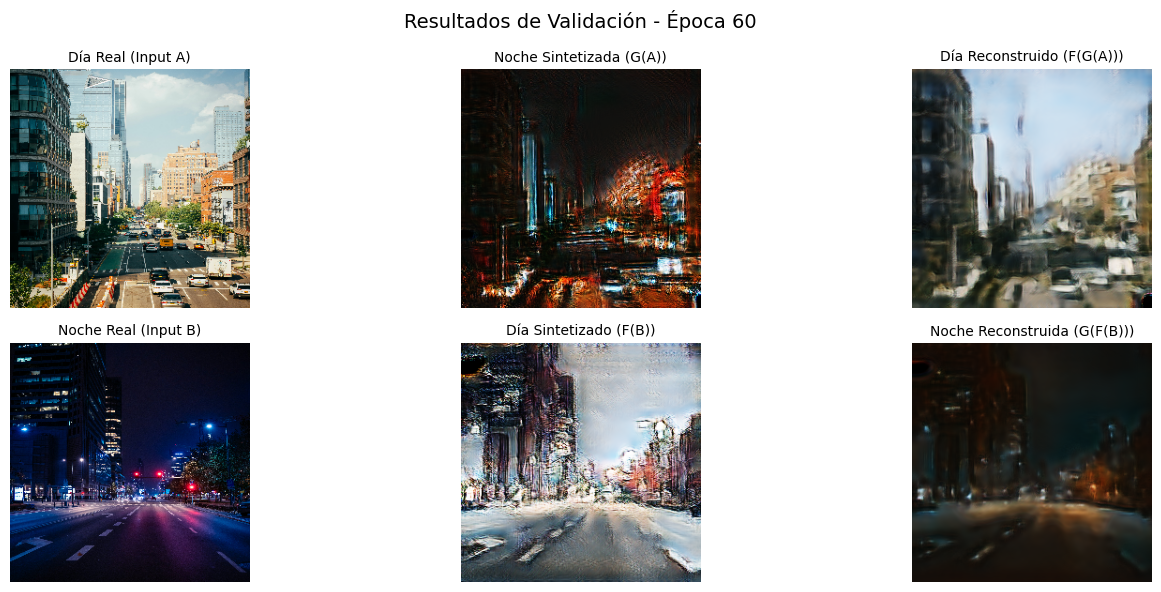

Checkpoint guardado en: ./checkpoints/cyclegan_day2night/ckpt-13
Época 60/60 completada en 241.9s | G_loss: 5.539 | D_loss: 0.530 | Cycle_loss: 3.452
Entrenamiento finalizado exitosamente.


In [ ]:
# Configuración de Checkpoints
checkpoint_dir = "./checkpoints/cyclegan_day2night"
os.makedirs(checkpoint_dir, exist_ok=True)

ckpt = tf.train.Checkpoint(generator_g=generator_g,
                           generator_f=generator_f,
                           discriminator_x=discriminator_x,
                           discriminator_y=discriminator_y,
                           generator_g_optimizer=generator_g_optimizer,
                           generator_f_optimizer=generator_f_optimizer,
                           discriminator_x_optimizer=discriminator_x_optimizer,
                           discriminator_y_optimizer=discriminator_y_optimizer)
ckpt_manager = tf.train.CheckpointManager(ckpt, checkpoint_dir, max_to_keep=3)

# Restaurar último checkpoint si existe (permite reanudar entrenamiento en local si se pausó)
if ckpt_manager.latest_checkpoint:
    ckpt.restore(ckpt_manager.latest_checkpoint)
    print(f"🔄 Checkpoint restaurado exitosamente desde: {ckpt_manager.latest_checkpoint}")
else:
    print("🆕 No se encontraron checkpoints previos. Iniciando entrenamiento desde cero.")

# Paso de entrenamiento compilado en grafo estático
@tf.function
def train_step(real_x, real_y, fake_x_buffered, fake_y_buffered):
    with tf.GradientTape(persistent=True) as tape:
        # Generación directa y reconstrucción cíclica
        fake_y = generator_g(real_x, training=True)
        cycled_x = generator_f(fake_y, training=True)

        fake_x = generator_f(real_y, training=True)
        cycled_y = generator_g(fake_x, training=True)

        # Pérdida de identidad
        same_x = generator_f(real_x, training=True)
        same_y = generator_g(real_y, training=True)

        # Discriminadores evaluando muestras reales y muestras falsas
        disc_real_x = discriminator_x(real_x, training=True)
        disc_real_y = discriminator_y(real_y, training=True)
        disc_fake_x = discriminator_x(fake_x, training=True)
        disc_fake_y = discriminator_y(fake_y, training=True)

        # Pérdida adversarial de generadores
        gen_g_loss = generator_loss(disc_fake_y)
        gen_f_loss = generator_loss(disc_fake_x)

        # Pérdida de ciclo e identidad
        total_cycle_loss = calc_cycle_loss(real_x, cycled_x) + calc_cycle_loss(real_y, cycled_y)
        id_loss_g = calc_identity_loss(real_y, same_y)
        id_loss_f = calc_identity_loss(real_x, same_x)

        total_gen_g_loss = gen_g_loss + total_cycle_loss + id_loss_g
        total_gen_f_loss = gen_f_loss + total_cycle_loss + id_loss_f

        # Discriminadores entrenados con las imágenes buffered (estabilización)
        disc_fake_buf_x = discriminator_x(fake_x_buffered, training=True)
        disc_fake_buf_y = discriminator_y(fake_y_buffered, training=True)

        disc_x_loss = discriminator_loss(disc_real_x, disc_fake_buf_x)
        disc_y_loss = discriminator_loss(disc_real_y, disc_fake_buf_y)

    # Cálculo de gradientes
    gen_g_grads = tape.gradient(total_gen_g_loss, generator_g.trainable_variables)
    gen_f_grads = tape.gradient(total_gen_f_loss, generator_f.trainable_variables)
    disc_x_grads = tape.gradient(disc_x_loss, discriminator_x.trainable_variables)
    disc_y_grads = tape.gradient(disc_y_loss, discriminator_y.trainable_variables)

    # Liberación explícita de tape para optimizar consumo de VRAM en la GPU de 6GB
    del tape

    # Aplicación de gradientes a los optimizadores
    generator_g_optimizer.apply_gradients(zip(gen_g_grads, generator_g.trainable_variables))
    generator_f_optimizer.apply_gradients(zip(gen_f_grads, generator_f.trainable_variables))
    discriminator_x_optimizer.apply_gradients(zip(disc_x_grads, discriminator_x.trainable_variables))
    discriminator_y_optimizer.apply_gradients(zip(disc_y_grads, discriminator_y.trainable_variables))

    return {
        "gen_g_loss": total_gen_g_loss,
        "gen_f_loss": total_gen_f_loss,
        "disc_x_loss": disc_x_loss,
        "disc_y_loss": disc_y_loss,
        "cycle_loss": total_cycle_loss,
        "fake_x": fake_x,
        "fake_y": fake_y
    }

# Muestras fijas de prueba para observar la evolución temporal
fixed_test_day = next(iter(test_dia))
fixed_test_night = next(iter(test_noche))

TOTAL_EPOCHS = 60       # Número recomendado de épocas para 200 imágenes
DECAY_START_EPOCH = 30  # Comienzo del decaimiento del learning rate
history = {"G_loss": [], "D_loss": [], "Cycle_loss": []}

print(f"Iniciando entrenamiento por {TOTAL_EPOCHS} épocas con {min(n_train_a, n_train_b)} pasos por época...")

for epoch in range(1, TOTAL_EPOCHS + 1):
    start = time.time()
    update_learning_rate(epoch, TOTAL_EPOCHS, DECAY_START_EPOCH)
    current_lr = float(generator_g_optimizer.learning_rate.numpy())

    ep_g_losses = []
    ep_d_losses = []
    ep_c_losses = []

    steps_total = min(n_train_a, n_train_b)
    pbar = tqdm(tf.data.Dataset.zip((train_dia, train_noche)), total=steps_total, desc=f"Época {epoch}/{TOTAL_EPOCHS}")

    for real_x, real_y in pbar:
        # Generar muestras preliminares para extraer del buffer
        fake_y_temp = generator_g(real_x, training=False)
        fake_x_temp = generator_f(real_y, training=False)
        fake_x_buffered = pool_fake_x.query(fake_x_temp)
        fake_y_buffered = pool_fake_y.query(fake_y_temp)

        step_losses = train_step(real_x, real_y, fake_x_buffered, fake_y_buffered)

        g_l = (step_losses["gen_g_loss"] + step_losses["gen_f_loss"]) * 0.5
        d_l = (step_losses["disc_x_loss"] + step_losses["disc_y_loss"]) * 0.5
        c_l = step_losses["cycle_loss"]

        ep_g_losses.append(g_l.numpy())
        ep_d_losses.append(d_l.numpy())
        ep_c_losses.append(c_l.numpy())

        pbar.set_postfix({
            "G_Loss": f"{g_l.numpy():.2f}",
            "D_Loss": f"{d_l.numpy():.2f}",
            "Cycle": f"{c_l.numpy():.2f}",
            "LR": f"{current_lr:.1e}"
        })

    # Guardar métricas promedio de la época
    mean_g = float(np.mean(ep_g_losses))
    mean_d = float(np.mean(ep_d_losses))
    mean_c = float(np.mean(ep_c_losses))
    history["G_loss"].append(mean_g)
    history["D_loss"].append(mean_d)
    history["Cycle_loss"].append(mean_c)

    # Cada 5 épocas mostramos la predicción visual y guardamos checkpoint
    if epoch % 5 == 0 or epoch == 1:
        clear_output(wait=True)
        generate_and_display_images(generator_g, generator_f, fixed_test_day, fixed_test_night, epoch=epoch)
        ckpt_path = ckpt_manager.save()
        print(f"Checkpoint guardado en: {ckpt_path}")

    print(f"Época {epoch}/{TOTAL_EPOCHS} completada en {time.time() - start:.1f}s | G_loss: {mean_g:.3f} | D_loss: {mean_d:.3f} | Cycle_loss: {mean_c:.3f}")

print("Entrenamiento finalizado exitosamente.")

## 5. Curvas de Convergencia y Diagnóstico de Sobreentrenamiento
Graficamos la evolución de las pérdidas para validar la estabilidad adversarial:
* **Convergencia saludable:** `Cycle_loss` debe descender sostenidamente (la red aprende a preservar los edificios).
* **Equilibrio adversarial:** `D_loss` debe mantenerse estable entre $0.4$ y $0.7$ gracias al *Dropout* y al *Label Smoothing* (si $D_{loss} \rightarrow 0$, el discriminador habría ganado y sobreajustado).


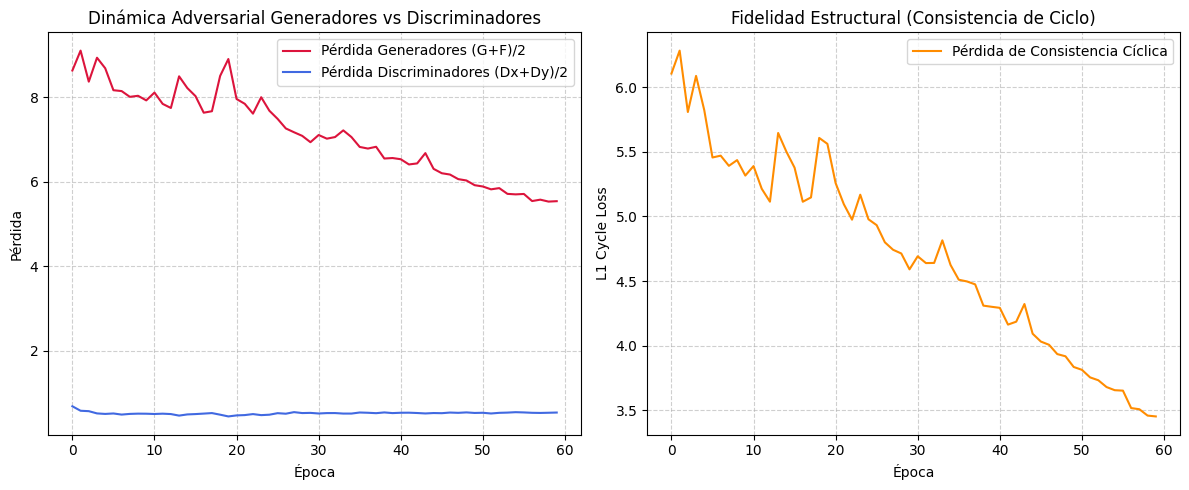

In [ ]:
# Graficar curvas de pérdidas
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history["G_loss"], label='Pérdida Generadores (G+F)/2', color='crimson')
plt.plot(history["D_loss"], label='Pérdida Discriminadores (Dx+Dy)/2', color='royalblue')
plt.title('Dinámica Adversarial Generadores vs Discriminadores')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["Cycle_loss"], label='Pérdida de Consistencia Cíclica', color='darkorange')
plt.title('Fidelidad Estructural (Consistencia de Ciclo)')
plt.xlabel('Época')
plt.ylabel('L1 Cycle Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()


## Evaluación Cuantitativa y Análisis Estadístico de Convergencia

Para complementar la inspección visual sobre el conjunto de prueba inédito (`testA`), se realiza una evaluación objetiva en dos niveles:

1. **Análisis por Fases de Entrenamiento (60 Épocas):** Se segmenta el historial de pérdidas (`history`) en tres etapas de 20 épocas cada una para cuantificar la estabilidad del equilibrio adversarial entre generadores y discriminadores, así como la reducción progresiva de la pérdida de consistencia cíclica ($\mathcal{L}_{cycle}$) tras activar el decaimiento de la tasa de aprendizaje (*LR Decay*).
2. **Métricas de Fidelidad Estructural y Reconstrucción Cíclica:** Utilizando los generadores entrenados $G$ ($\text{Día} \to \text{Noche}$) y $F$ ($\text{Noche} \to \text{Día}$), se evalúa el ciclo completo $F(G(x)) \approx x$ sobre todas las imágenes de `testA` mediante:
   * **SSIM (*Structural Similarity Index Measure*):** Mide la preservación de estructuras espaciales, bordes y geometría urbana (rango $[0, 1]$, ideal cercano a $1.0$).
   * **PSNR (*Peak Signal-to-Noise Ratio*):** Cuantifica la fidelidad de reconstrucción a nivel de píxel en decibelios ($\text{dB}$).
   * **Error $L_1$ de Ciclo en Prueba:** Verifica que la pérdida de reconstrucción en datos nunca vistos sea consistente con la observada al final del entrenamiento.

In [ ]:
import datetime
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display

# Detectar dinámicamente las claves guardadas en history
if 'history' not in globals() or not history.get("G_loss"):
    print("Aviso: 'history' no contiene registros en la sesión actual. Ejecuta el entrenamiento primero.")
else:
    keys_disponibles = list(history.keys())
    print("Claves detectadas en history:", keys_disponibles)

    df_history = pd.DataFrame(history)
    df_history['Epoca'] = np.arange(1, len(df_history) + 1)

    # Dividir en 3 fases de 20 épocas (o tercios dinámicos según total de épocas)
    total_epocas = len(df_history)
    bins = [0, max(1, total_epocas // 3), max(2, (2 * total_epocas) // 3), total_epocas]
    labels = [
        f"Fase 1 (Épocas 1-{bins[1]}): Exploración",
        f"Fase 2 (Épocas {bins[1]+1}-{bins[2]}): Estabilización",
        f"Fase 3 (Épocas {bins[2]+1}-{bins[3]}): Refinamiento (LR Decay)"
    ]
    df_history['Fase'] = pd.cut(df_history['Epoca'], bins=bins, labels=labels)

    # Resumen estadístico (Media y Desviación Estándar por fase)
    resumen_fases = df_history.groupby('Fase', observed=False)[keys_disponibles].agg(['mean', 'std'])
    print("
=== Resumen Estadístico por Fases de Entrenamiento ===")
    display(resumen_fases.round(4))

    # Porcentaje de mejora en Cycle_loss desde la época 1 hasta la final
    if 'Cycle_loss' in df_history.columns and len(df_history['Cycle_loss']) > 1:
        c_ini = df_history['Cycle_loss'].iloc[0]
        c_fin = df_history['Cycle_loss'].iloc[-1]
        mejora_pct = ((c_ini - c_fin) / c_ini) * 100
        print(f"
Reducción total de L1 Cycle Loss: {c_ini:.4f} -> {c_fin:.4f} (-{mejora_pct:.2f}%)")

    log_dir = "logs/cyclegan_analisis_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    writer = tf.summary.create_file_writer(log_dir)

    with writer.as_default():
        for idx, row in df_history.iterrows():
            ep = int(row['Epoca'])
            for k in keys_disponibles:
                tf.summary.scalar(f"Metricas_Entrenamiento/{k}", row[k], step=ep)
    writer.flush()
    print(f"
Logs de TensorBoard exportados en: {log_dir}")

# Usa el dataset de prueba disponible en memoria (test_dia o testA)
dataset_prueba = test_dia if 'test_dia' in globals() else testA

ssim_list, psnr_list, l1_test_list = [], [], []

for batch_dia in dataset_prueba:
    # Ciclo completo: Día -> Noche (G) -> Día Reconstruido (F)
    fake_noche = generator_g(batch_dia, training=False)
    rec_dia = generator_f(fake_noche, training=False)

    # Desnormalizar de [-1, 1] a [0, 1] para métricas de imagen
    img_real_01 = tf.clip_by_value((batch_dia + 1.0) / 2.0, 0.0, 1.0)
    img_rec_01 = tf.clip_by_value((rec_dia + 1.0) / 2.0, 0.0, 1.0)

    ssim_val = tf.image.ssim(img_real_01, img_rec_01, max_val=1.0).numpy()
    psnr_val = tf.image.psnr(img_real_01, img_rec_01, max_val=1.0).numpy()
    l1_val = tf.reduce_mean(tf.abs(batch_dia - rec_dia)).numpy()

    ssim_list.extend(np.atleast_1d(ssim_val))
    psnr_list.extend(np.atleast_1d(psnr_val))
    l1_test_list.append(l1_val)

df_metricas_test = pd.DataFrame({
    'Métrica': ['SSIM (Similitud Estructural)', 'PSNR (Relación Señal/Ruido)', 'L1 Cycle Error (Test Inédito)'],
    'Promedio': [np.mean(ssim_list), np.mean(psnr_list), np.mean(l1_test_list)],
    'Desv. Estándar': [np.std(ssim_list), np.std(psnr_list), np.std(l1_test_list)],
    'Mínimo': [np.min(ssim_list), np.min(psnr_list), np.min(l1_test_list)],
    'Máximo': [np.max(ssim_list), np.max(psnr_list), np.max(l1_test_list)]
})

print("
=== Métricas Cuantitativas de Consistencia Cíclica sobre testA ===")
display(df_metricas_test.round(4))

Archivos de modelo encontrados: Ninguno en disco local


## 6. Evaluación Cualitativa Final sobre el Conjunto de Prueba Inédito (`testA`)
Evaluamos el modelo final en imágenes de día que la red **nunca vio durante el entrenamiento**, analizando:
1. Oscurecimiento coherente del cielo.
2. Iluminación nocturna y contraste en ventanas y farolas de edificios.
3. Preservación nítida de líneas y bordes urbanos.


Evaluando generador en imágenes inéditas de prueba (Día -> Noche)...


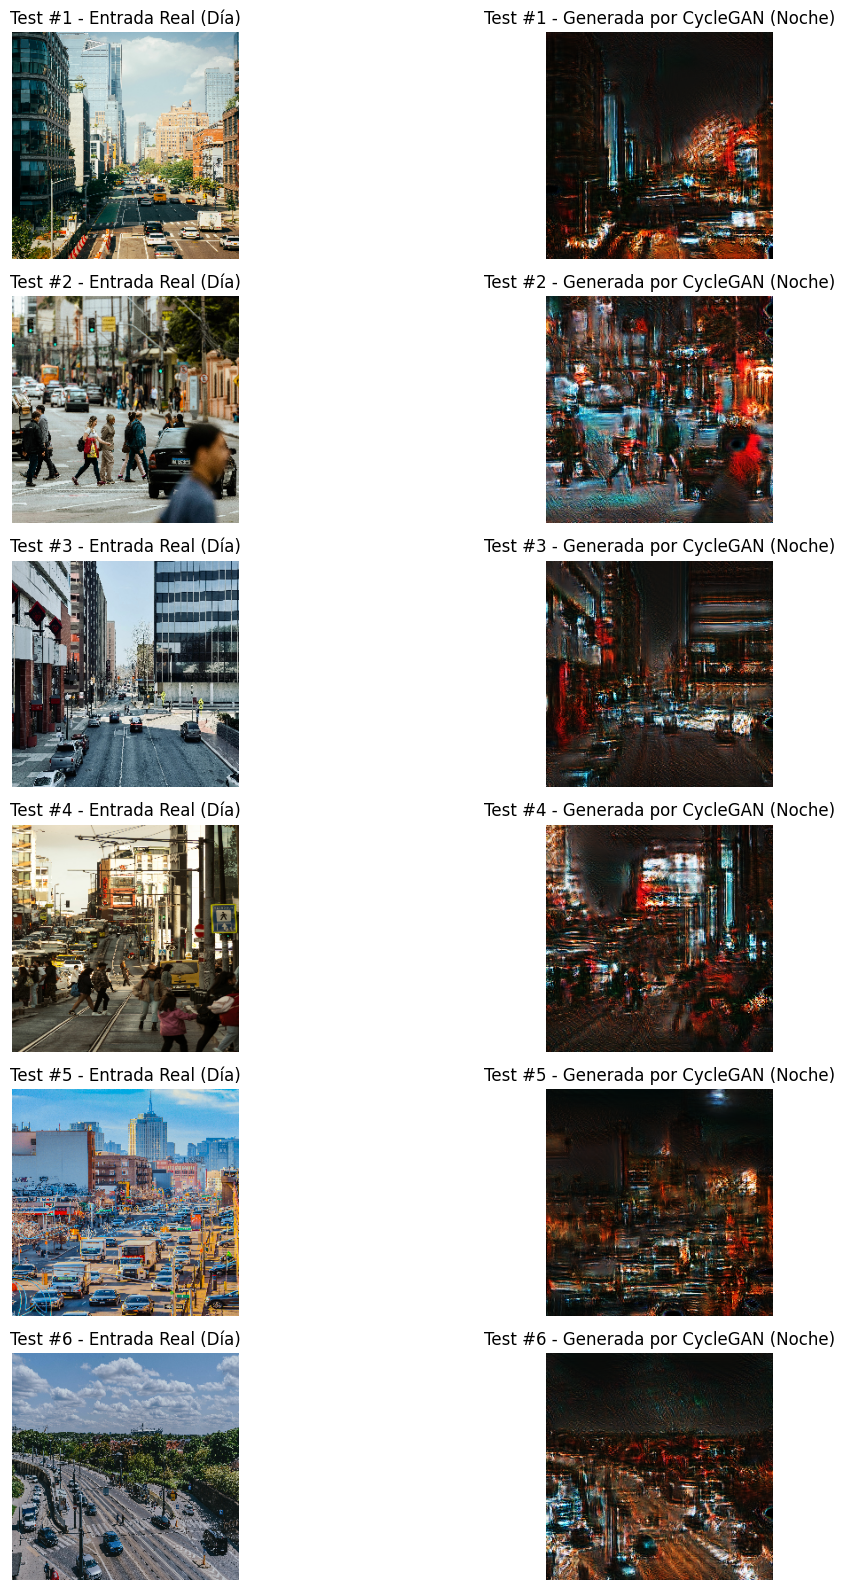

In [ ]:
# Evaluación con 8 muestras inéditas de testA
print("Evaluando generador en imágenes inéditas de prueba (Día -> Noche)...")

plt.figure(figsize=(14, 16))
test_samples = list(test_dia.take(6))

for idx, day_img in enumerate(test_samples):
    fake_night_img = generator_g(day_img, training=False)

    # Imagen real de día
    plt.subplot(6, 2, idx * 2 + 1)
    plt.imshow(day_img[0] * 0.5 + 0.5)
    plt.title(f"Test #{idx + 1} - Entrada Real (Día)")
    plt.axis('off')

    # Imagen sintética nocturna
    plt.subplot(6, 2, idx * 2 + 2)
    plt.imshow(fake_night_img[0] * 0.5 + 0.5)
    plt.title(f"Test #{idx + 1} - Generada por CycleGAN (Noche)")
    plt.axis('off')

plt.tight_layout()
plt.show()


## 7. Exportación y Guardado de los Modelos Entrenados
Guardamos los pesos del generador `generator_g` (Día $\rightarrow$ Noche) en formato nativo Keras (`.keras`) y en formato H5 (`.h5`) siguiendo la técnica de guardado vista en `Gan_RED.ipynb` para su fácil descarga o despliegue.


In [ ]:
# Exportar modelos generadores finales
os.makedirs("modelos_exportados", exist_ok=True)

# Guardado en formato moderno .keras y tradicional .h5 de ambos generadores
generator_g.save("modelos_exportados/cyclegan_dia_a_noche.keras")
generator_g.save("modelos_exportados/cyclegan_dia_a_noche.h5")

generator_f.save("modelos_exportados/cyclegan_noche_a_dia.keras")
generator_f.save("modelos_exportados/cyclegan_noche_a_dia.h5")

print("Generadores guardados exitosamente en:")
print(" - Día -> Noche: modelos_exportados/cyclegan_dia_a_noche.keras / .h5")
print(" - Noche -> Día: modelos_exportados/cyclegan_noche_a_dia.keras / .h5")

Generador Día -> Noche guardado exitosamente en:
 - modelos_exportados/cyclegan_dia_a_noche.keras
 - modelos_exportados/cyclegan_dia_a_noche.h5


## Prueba Final con Imágenes Personalizadas
Para evaluar la capacidad de generalización de nuestros generadores entrenados ($G_{A \to B}$ para convertir Día a Noche, y $F_{B \to A}$ para convertir Noche a Día) sobre escenas externas al conjunto de entrenamiento/evaluación original:
* Se cargan las imágenes ubicadas en `RepositorioMiniproyecto3/prueba final/dia` y `RepositorioMiniproyecto3/prueba final/noche`.
* Se preprocesan al tamaño de entrada de la red (`256x256`) y se normalizan al rango $[-1, 1]$.
* Se generan las traducciones correspondientes, se visualizan comparativamente y se exportan las imágenes resultantes en alta calidad dentro de `RepositorioMiniproyecto3/prueba final/resultados`.

In [ ]:
import glob
from PIL import Image

# 1. Definir rutas según la estructura del entorno local (VS Code) o Colab
POSSIBLE_TEST_DIRS = [
    "prueba final",
    "./prueba final",
    "RepositorioMiniproyecto3/prueba final",
    "/content/RepositorioMiniproyecto3/prueba final"
]
base_prueba = next((p for p in POSSIBLE_TEST_DIRS if os.path.exists(p)), "prueba final")

ruta_dia = os.path.join(base_prueba, "dia")
ruta_noche = os.path.join(base_prueba, "noche")
ruta_resultados = os.path.join(base_prueba, "resultados")
os.makedirs(ruta_resultados, exist_ok=True)

print(f"Directorio de prueba final seleccionado: '{base_prueba}'")

# 2. Detectar el nombre de las variables de los generadores en memoria o cargarlos de disco
gen_dia_a_noche = globals().get('generator_g') or globals().get('G') or globals().get('gen_A2B')
gen_noche_a_dia = globals().get('generator_f') or globals().get('F') or globals().get('gen_B2A')

# Si no están en memoria, intentar cargarlos de los checkpoints o modelos exportados
if gen_dia_a_noche is None and os.path.exists("modelos_exportados/cyclegan_dia_a_noche.keras"):
    try:
        gen_dia_a_noche = tf.keras.models.load_model(
            "modelos_exportados/cyclegan_dia_a_noche.keras",
            custom_objects={'InstanceNormalization': InstanceNormalization, 'ReflectionPadding2D': ReflectionPadding2D}
        )
        print("Cargado generator_g desde modelos_exportados/cyclegan_dia_a_noche.keras")
    except Exception as e:
        print("Aviso al cargar modelo exportado G:", e)

if gen_noche_a_dia is None and os.path.exists("modelos_exportados/cyclegan_noche_a_dia.keras"):
    try:
        gen_noche_a_dia = tf.keras.models.load_model(
            "modelos_exportados/cyclegan_noche_a_dia.keras",
            custom_objects={'InstanceNormalization': InstanceNormalization, 'ReflectionPadding2D': ReflectionPadding2D}
        )
        print("Cargado generator_f desde modelos_exportados/cyclegan_noche_a_dia.keras")
    except Exception as e:
        print("Aviso al cargar modelo exportado F:", e)

if gen_dia_a_noche is None or gen_noche_a_dia is None:
    raise NameError("No se encontraron los modelos generadores en memoria ni en disco. Ejecuta las celdas de construcción/entrenamiento primero.")

# 3. Funciones auxiliares de carga y guardado
def cargar_y_preprocesar(ruta_imagen):
    img_raw = tf.io.read_file(ruta_imagen)
    img = tf.image.decode_image(img_raw, channels=3, expand_animations=False)
    img_original = tf.cast(img, tf.uint8).numpy()
    # Redimensionar a 256x256 y normalizar a [-1, 1]
    img_resized = tf.image.resize(img, [256, 256], method=tf.image.ResizeMethod.BICUBIC)
    img_norm = (tf.cast(img_resized, tf.float32) / 127.5) - 1.0
    return tf.expand_dims(img_norm, 0), img_original

def guardar_imagen_generada(tensor_salida, ruta_destino):
    # Desnormalizar de [-1, 1] a [0, 255]
    img_array = ((tensor_salida[0].numpy() + 1.0) * 127.5)
    img_array = np.clip(img_array, 0, 255).astype(np.uint8)
    Image.fromarray(img_array).save(ruta_destino)
    return img_array

# Buscar imágenes en ambas carpetas (soporta jpg, jpeg, png, webp)
extensiones = ('*.jpg', '*.jpeg', '*.png', '*.webp', '*.JPG', '*.PNG')
imagenes_dia = [f for ext in extensiones for f in glob.glob(os.path.join(ruta_dia, ext))]
imagenes_noche = [f for ext in extensiones for f in glob.glob(os.path.join(ruta_noche, ext))]

print(f"Imágenes encontradas -> Día: {len(imagenes_dia)} | Noche: {len(imagenes_noche)}")

# 4. Procesar y guardar transformación DÍA -> NOCHE
for idx, ruta_img in enumerate(imagenes_dia):
    nombre_base = os.path.splitext(os.path.basename(ruta_img))[0]
    tensor_in, img_orig = cargar_y_preprocesar(ruta_img)
    prediccion = gen_dia_a_noche(tensor_in, training=False)

    ruta_guardado = os.path.join(ruta_resultados, f"resultado_dia_a_noche_{nombre_base}.png")
    img_generada = guardar_imagen_generada(prediccion, ruta_guardado)

    # Visualización
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(tf.image.resize(img_orig, [256, 256]).numpy().astype(np.uint8))
    axes[0].set_title(f"Original (Día): {nombre_base}")
    axes[0].axis("off")

    axes[1].imshow(img_generada)
    axes[1].set_title("Generada (Noche)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    print(f"Guardada en: {ruta_guardado}")

# 5. Procesar y guardar transformación NOCHE -> DÍA
for idx, ruta_img in enumerate(imagenes_noche):
    nombre_base = os.path.splitext(os.path.basename(ruta_img))[0]
    tensor_in, img_orig = cargar_y_preprocesar(ruta_img)
    prediccion = gen_noche_a_dia(tensor_in, training=False)

    ruta_guardado = os.path.join(ruta_resultados, f"resultado_noche_a_dia_{nombre_base}.png")
    img_generada = guardar_imagen_generada(prediccion, ruta_guardado)

    # Visualización
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(tf.image.resize(img_orig, [256, 256]).numpy().astype(np.uint8))
    axes[0].set_title(f"Original (Noche): {nombre_base}")
    axes[0].axis("off")

    axes[1].imshow(img_generada)
    axes[1].set_title("Generada (Día)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    print(f"Guardada en: {ruta_guardado}")